# Data analysis, experiment 1

In [1]:
!source ../.venv/bin/activate

import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

from lmfocus.results import gather_data_accuracy
from lmfocus.utils import (
    MODEL_NAME_MAPPING,
    GEMMA_MODELS,
    QWEN_3_MODELS,
    QWEN_35_MODELS,
    MODEL_SIZES,
    TestType,
    DATA_TYPE_TRANSLATION,
    CATEGORY_TRANSLATION,
    FM_TRANSLATION,
    METHODS_PALETTE,
    RANDOM_FOCUS_MARKERS
)

results_folder = "../data/results"

sns.set_theme(font='Cronos Pro', style='whitegrid', palette='deep')
plt.subplots_adjust(hspace = 0.1)

<Figure size 640x480 with 0 Axes>

## Gather data for original and revised datasets into two dataframes

In [2]:
gemma_data_target = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

gemma_data_control = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_3_data_target = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_3_data_control = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_35_data_target = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_35_data_control = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2,
    control = True,
    focus_markers = RANDOM_FOCUS_MARKERS
)

gemma_data_target['condition'] = 'Target'
qwen_3_data_target['condition'] = 'Target'
qwen_35_data_target['condition'] = 'Target'

gemma_data_control['condition'] = 'Control'
qwen_3_data_control['condition'] = 'Control'
qwen_35_data_control['condition'] = 'Control'

data = pd.concat([
    gemma_data_target,
    gemma_data_control,
    qwen_3_data_target,
    qwen_3_data_control,
    qwen_35_data_target,
    qwen_35_data_control
])

data['fm_type'] = 'Ad Hoc'

In [3]:
data.shape

(479400, 8)

## Save data to CSVs for stats

In [4]:
data.to_csv('../stats/exp_02_results.csv', index = False)

## Dictionaries for translating methods, model names, and category names for graphs

## Graph method comparison

In [5]:
def model_to_model_family(model_name: str):
    if model_name.startswith('gemma'):
        return 'Gemma 4'
    elif model_name.startswith('qwen_3.5'):
        return 'Qwen3.5'
    else:
        return 'Qwen3'

In [6]:
data['Method'] = data['data_type'].apply(lambda x: DATA_TYPE_TRANSLATION[x])
data['model_nat'] = data['model'].apply(lambda x: MODEL_NAME_MAPPING[x])
data['category'] = data['category'].apply(lambda x: CATEGORY_TRANSLATION[x])
data['model_size'] = data['model'].apply(lambda x: MODEL_SIZES[x])
data['model_family'] = data['model'].apply(model_to_model_family)
data['model_family_and_condition'] = data['model_family'] + ', ' + data['condition']

In [7]:
data.head()

,original_data_index,correct,focus_marker,data_type,category,model,condition,fm_type,Method,model_nat,model_size,model_family,model_family_and_condition
0,0,False,random_bracket_0,string_probs,ONLY,gemma_4_E2B,Target,Ad Hoc,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
1,1,True,random_bracket_0,string_probs,ONLY,gemma_4_E2B,Target,Ad Hoc,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
2,2,True,random_bracket_0,string_probs,ONLY,gemma_4_E2B,Target,Ad Hoc,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
3,3,True,random_bracket_0,string_probs,ONLY,gemma_4_E2B,Target,Ad Hoc,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"
4,4,True,random_bracket_0,string_probs,ONLY,gemma_4_E2B,Target,Ad Hoc,SP,Gemma 4 E2B,2.0,Gemma 4,"Gemma 4, Target"


In [8]:
def method_comp_plot(model_family: str, include_legend: bool = True, include_controls: bool = True):
    sub_data = data.copy()
    if not include_controls:
        sub_data = sub_data[sub_data['condition'] == 'Target']
    sub_data = sub_data[sub_data['model_family'] == model_family]
    g = sns.catplot(
        data=sub_data,
        hue='Method',
        hue_order=['YN2', 'YN1', 'FC2', 'FC1', 'SP'],
        y='correct',
        x='model_size',
        kind='point',
        col='condition',
        col_order = ['Target', 'Control'],
        native_scale=True,
        palette=METHODS_PALETTE,
        estimator=lambda x: (sum(x) / len(x)) * 100,
        col_wrap=2,
        height=2.5,
        aspect=1.8
    )

    if include_controls:
        g.set_titles('{col_name}')
    else:
        g.set_titles('')
    
    for ax in g.axes.flat:
        ax.grid(axis='x', visible=False)
        # ax.set_xticks(data['model_size'].unique())
        ax.set_ylim(top=100)
        x_label = 'Parameters (Billions)' if include_legend else ''
        ax.set_xlabel(x_label)
        ax.set_ylabel('Accuracy (%)')
        ax.axhline(
            50,
            linestyle=':',
            color='black',
            linewidth=1.5,
        )
        ax.set_xscale('log')
        ax.minorticks_off()
        x_ticks = sorted(sub_data['model_size'].dropna().unique())

        ax.set_xticks(x_ticks)
        ax.set_xticklabels([
            f'{x:g}' for x in x_ticks
        ])
        for line in ax.lines:
            line.set_linewidth(1.5)
            line.set_markersize(2)
    
    legend = g.legend
    
    # Get its handles and labels
    handles = list(reversed(legend.legend_handles))
    # handles = [handles[0], handles[3], handles[1], handles[4], handles[2]]
    labels = list(reversed([text.get_text() for text in legend.texts]))
    # labels = [labels[0], labels[3], labels[1], labels[4], labels[2]]
    
    # Add chance line
    handles.append(
        Line2D(
            [0], [0],
            color='black',
            linestyle=':',
            linewidth=1.5
        )
    )
    labels.append('Chance')
    
    # Remove old legend
    legend.remove()
    
    # Recreate it
    if include_legend:
        g.figure.legend(
            handles=handles,
            labels=labels,
            title='',
            bbox_to_anchor = (0.5, -.15),
            loc='lower center',
            ncols = 6,
            framealpha = 1
        )
    g.figure.suptitle(model_family, y=1.03)

    # g.set_xticklabels(rotation=-45)
    return g

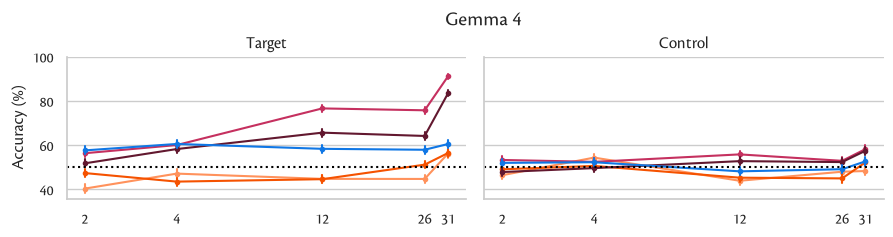

In [9]:
gemma_plot_method_comp = method_comp_plot("Gemma 4", include_legend=False)
gemma_plot_method_comp.savefig('../graphs/03a_gemma_methods_exp2.png')

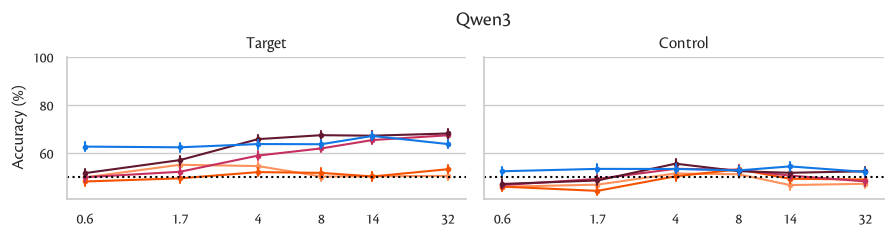

In [10]:
qwen_3_plot_method_comp = method_comp_plot("Qwen3", include_legend=False)
qwen_3_plot_method_comp.savefig('../graphs/03b_qwen3_methods_exp2.png')

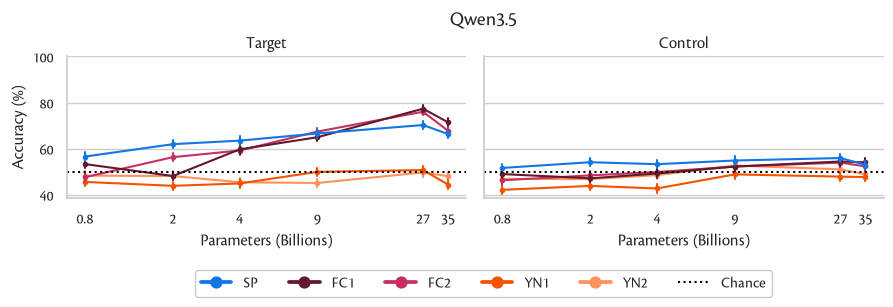

In [11]:
qwen_35_plot_method_comp = method_comp_plot("Qwen3.5")
qwen_35_plot_method_comp.savefig('../graphs/03c_qwen35_methods_exp2.png')

In [12]:
def make_stats(data, model_family):
    out_df = data[(data['model_family'] == model_family) & (data['condition'] == 'Target')]
    model_list = out_df['model'].unique()
    out_df = out_df.groupby(['model', 'data_type'])[['correct']].agg('mean')
    out_df = out_df.reset_index().pivot(index='model', columns = 'data_type', values = 'correct')
    out_df = out_df[['string_probs', 'forced_choice_1', 'forced_choice_2', 'yes_no_1', 'yes_no_2']]
    out_df = out_df.apply(lambda x: round(x * 100, 1))
    out_df = out_df.reindex(model_list)
    # out_df['model_family'] = model_family
    return out_df

In [13]:
make_stats(data, 'Gemma 4')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
gemma_4_E2B,57.6,51.7,56.3,47.3,40.3
gemma_4_E4B,60.5,58.2,60.0,43.5,47.1
gemma_4_12B,58.3,65.6,76.6,44.6,44.7
gemma_4_26B_A4B,57.9,64.1,75.7,51.1,44.7
gemma_4_31B,60.5,83.3,91.0,56.4,56.1


In [14]:
make_stats(data, 'Qwen3')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3_0.6B,62.6,51.5,49.8,48.0,49.8
qwen_3_1.7B,62.3,57.0,52.1,49.4,55.0
qwen_3_4B,63.6,65.7,58.8,52.0,54.5
qwen_3_8B,63.5,67.3,61.8,51.6,50.1
qwen_3_14B,67.0,67.1,65.3,50.1,50.2
qwen_3_32B,63.6,68.0,67.3,53.2,50.4


In [15]:
make_stats(data, 'Qwen3.5')

data_type,string_probs,forced_choice_1,forced_choice_2,yes_no_1,yes_no_2
model,,,,,
qwen_3.5_0.8B,56.6,53.3,47.6,45.6,48.3
qwen_3.5_2B,62.0,48.1,56.3,43.9,48.1
qwen_3.5_4B,63.5,59.7,59.2,44.9,45.4
qwen_3.5_9B,66.6,65.0,67.4,49.9,45.1
qwen_3.5_27B,70.2,77.3,76.0,50.7,49.7
qwen_3.5_35B_A3B,66.3,71.5,67.8,44.4,48.0


In [16]:
def map_model_to_model_size(model_str):
    for start_string in ['gemma_4_', 'qwen_3_', 'qwen_3.5_']:
        if model_str.startswith(start_string):
            return '-'.join(model_str[len(start_string):].split('_'))
    return 'NO_MODEL'
    

In [17]:
def combine_old_and_new(df_old, df_new):
    col_names = ['string_probs', 'forced_choice_1', 'forced_choice_2', 'yes_no_1', 'yes_no_2']
    
    for col_name in col_names:
        df_new[f'{col_name}_change'] = df_new[col_name] - df_old[col_name]
    df_new = df_new[[f'{col_name}_change' for col_name in col_names]]
    df_new = df_new.rename(columns = {
        'string_probs_change': 'SP',
        'forced_choice_1_change': 'FC1',
        'forced_choice_2_change': 'FC2',
        'yes_no_1_change': 'YN1',
        'yes_no_2_change': 'YN2'
    }, index = map_model_to_model_size)
    return df_new

In [18]:
gemma_data_target_original = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
)

qwen_3_data_target_original = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2
)

qwen_35_data_target_original = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2
)

gemma_data_target_original['condition'] = 'Target'
qwen_3_data_target_original['condition'] = 'Target'
qwen_35_data_target_original['condition'] = 'Target'

data_original = pd.concat([gemma_data_target_original, qwen_3_data_target_original, qwen_35_data_target_original])
data_original['model_family'] = data_original['model'].apply(model_to_model_family)

In [19]:
gemma_df_old, gemma_df_new = make_stats(data_original, 'Gemma 4'), make_stats(data, 'Gemma 4')
gemma_exp_comp = combine_old_and_new(gemma_df_old, gemma_df_new)
qwen_3_df_old, qwen_3_df_new = make_stats(data_original, 'Qwen3'), make_stats(data, 'Qwen3')
qwen_3_exp_comp = combine_old_and_new(qwen_3_df_old, qwen_3_df_new)
qwen_35_df_old, qwen_35_df_new = make_stats(data_original, 'Qwen3.5'), make_stats(data, 'Qwen3.5')
qwen_35_exp_comp = combine_old_and_new(qwen_35_df_old, qwen_35_df_new)

combined_exp_comp = pd.concat([gemma_exp_comp, qwen_3_exp_comp, qwen_35_exp_comp])

values = [item for _, row in combined_exp_comp.iterrows() for item in list(row)]
min_value = min(values)
max_value = max(values)
mean_value = pd.Series(values).mean()

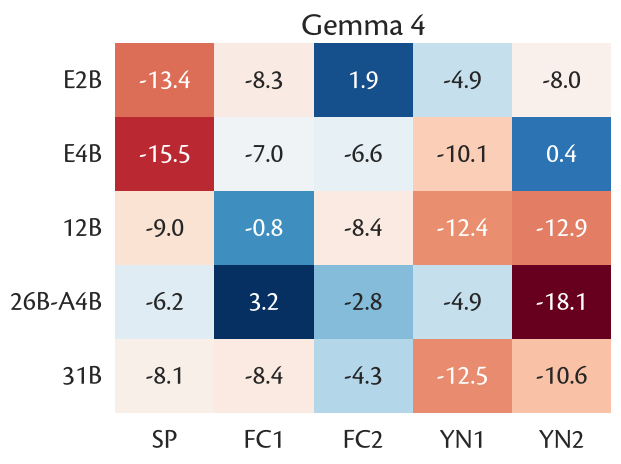

In [20]:
gemma_heatmap = sns.heatmap(gemma_exp_comp, annot=True, annot_kws={"size": 20}, cmap='RdBu', fmt=".1f", cbar=False)
gemma_heatmap.set_ylabel(None)
gemma_heatmap.set_xlabel(None)
gemma_heatmap.tick_params(axis='both', which='major', labelsize=20, rotation=0)
gemma_heatmap.set_title('Gemma 4', fontdict={'size': 24})
gemma_fig = gemma_heatmap.get_figure()
gemma_fig.savefig('../graphs/04a_gemma_exp_comp.png', bbox_inches = 'tight')

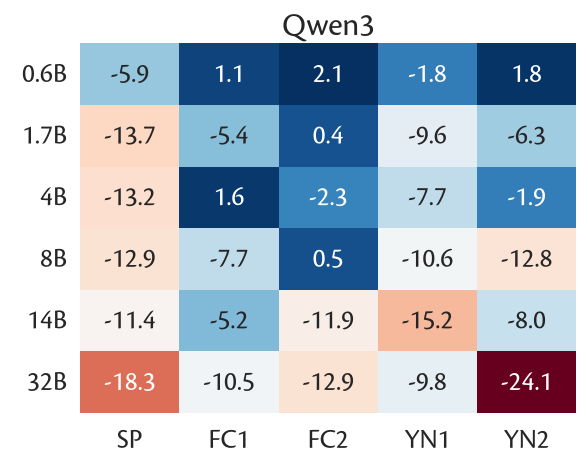

In [21]:
yticklabels = [f'  {index_value}' for index_value in qwen_3_exp_comp.index]
qwen_3_heatmap = sns.heatmap(qwen_3_exp_comp, annot=True, annot_kws={"size": 20}, cmap='RdBu', fmt=".1f", cbar=False, yticklabels=yticklabels)
qwen_3_heatmap.set_ylabel(None)
qwen_3_heatmap.set_xlabel(None)
qwen_3_heatmap.tick_params(axis='both', which='major', labelsize=20, rotation=0)
qwen_3_heatmap.set_title('Qwen3', fontdict={'size': 24})
qwen_3_fig = qwen_3_heatmap.get_figure()
qwen_3_fig.savefig('../graphs/04b_qwen_3_exp_comp.png', bbox_inches = 'tight')

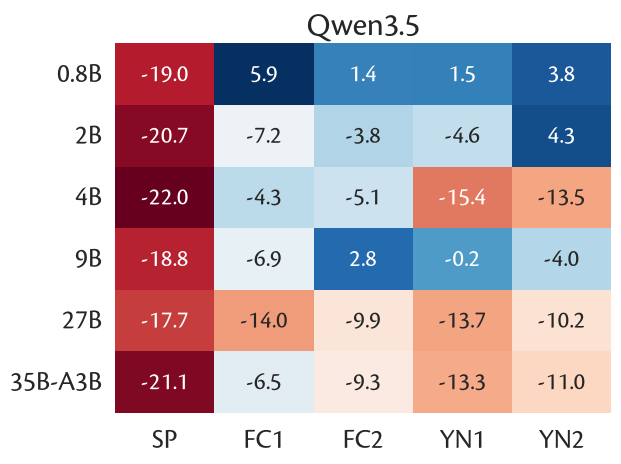

In [22]:
qwen_35_heatmap = sns.heatmap(qwen_35_exp_comp, annot=True, annot_kws={"size": 18}, cmap='RdBu', fmt=".1f", cbar=False)
qwen_35_heatmap.set_ylabel(None)
qwen_35_heatmap.set_xlabel(None)
qwen_35_heatmap.tick_params(axis='both', which='major', labelsize=20, rotation=0)
qwen_35_heatmap.set_title('Qwen3.5', fontdict={'size': 24})
qwen_35_fig = qwen_35_heatmap.get_figure()
qwen_35_fig.savefig('../graphs/04c_qwen_35_exp_comp.png', bbox_inches='tight')

In [23]:
gemma_exp_comp_copy = gemma_exp_comp.copy()
qwen_3_exp_comp_copy = qwen_3_exp_comp.copy()
qwen_35_exp_comp_copy = qwen_35_exp_comp.copy()
gemma_exp_comp_copy['model_family'] = 'Gemma 4'
qwen_3_exp_comp_copy['model_family'] = 'Qwen3'
qwen_35_exp_comp_copy['model_family'] = 'Qwen3.5'

exp_comps = pd.concat([gemma_exp_comp_copy, qwen_3_exp_comp_copy, qwen_35_exp_comp_copy])

In [24]:
exp_comps

data_type,SP,FC1,FC2,YN1,YN2,model_family
model,,,,,,
E2B,-13.4,-8.3,1.9,-4.9,-8.0,Gemma 4
E4B,-15.5,-7.0,-6.6,-10.1,0.4,Gemma 4
12B,-9.0,-0.8,-8.4,-12.4,-12.9,Gemma 4
26B-A4B,-6.2,3.2,-2.8,-4.9,-18.1,Gemma 4
31B,-8.1,-8.4,-4.3,-12.5,-10.6,Gemma 4
0.6B,-5.9,1.1,2.1,-1.8,1.8,Qwen3
1.7B,-13.7,-5.4,0.4,-9.6,-6.3,Qwen3
4B,-13.2,1.6,-2.3,-7.7,-1.9,Qwen3
8B,-12.9,-7.7,0.5,-10.6,-12.8,Qwen3
